In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [3]:
tickers = [
    "KO", "PEP",
    "V", "MA",
    "XOM", "CVX",
    "HD", "LOW"
]

start_date = "2016-01-01"
end_date = "2026-01-01"

In [4]:
raw_data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    interval = "1d",
    auto_adjust = True,
    progress = False
)

raw_data.head()

Price           Close                                                          \
Ticker            CVX          HD         KO        LOW         MA        PEP   
Date                                                                            
2016-01-04  56.349918  101.842308  30.555971  61.658649  88.842903  71.665527   
2016-01-05  56.831917  101.345024  30.664070  61.789703  89.011566  72.158905   
2016-01-06  54.586800  100.296066  30.498302  60.561123  87.650108  72.180695   
2016-01-07  52.652439   97.436684  29.993851  59.029484  86.044533  70.794830   
2016-01-08  52.088009   96.271179  29.914589  58.054810  84.401375  70.533653   

Price                                  High              ...       Open  \
Ticker              V        XOM        CVX          HD  ...          V   
Date                                                     ...              
2016-01-04  70.156281  49.002316  57.149029  101.842308  ...  70.489917   
2016-01-05  70.684563  49.419853  56.857286  102.518312  ...  70.666030   
2016-01-06  69.757797  49.008648  55.671305  100.933206  ...  69.507573   
2016-01-07  68.386162  48.224205  54.383845   99.363658  ...  68.358360   
2016-01-08  67.542801  47.249977  53.172515   98.314706  ...  68.636387   

Price                    Volume                                        \
Ticker            XOM       CVX        HD        KO      LOW       MA   
Date                                                                    
2016-01-04  49.027621  11397300   8050900  16084100  6534600  6378700   
2016-01-05  48.831521   7883400   5320900  15781900  5198800  4352500   
2016-01-06  48.483577  14511400   8199600  16245100  5326500  4370000   
2016-01-07  48.116657  15368800  12551000  20563600  6401600  6600000   
2016-01-08  48.300115  11891600   7104500  14645900  5325500  5912100   

Price                                    
Ticker          PEP         V       XOM  
Date                                     
2016-01-04  6689000  13476800  20400100  
2016-01-05  4893800   8972700  11993500  
2016-01-06  5483400  16092000  18826900  
2016-01-07  5440000  12470800  21263800  
2016-01-08  4853500   9977600  19033600  

[5 rows x 40 columns]

EXTRACT CLOSING PRICES

In [8]:
prices = raw_data["Close"].copy()
prices.head()

# inspect shape of the data
print(prices.shape)
print(prices.columns)

(2514, 8)
Index(['CVX', 'HD', 'KO', 'LOW', 'MA', 'PEP', 'V', 'XOM'], dtype='object', name='Ticker')


CHECK MISSING DATA

In [ ]:
print(prices.isna().sum())
print(prices.shape)

Ticker
CVX    0
HD     0
KO     0
LOW    0
MA     0
PEP    0
V      0
XOM    0
dtype: int64
(2514, 8)


LOOK AT ACTUAL PRICES

In [14]:
prices.tail()

Ticker,CVX,HD,KO,LOW,MA,PEP,V,XOM
Date,,,,,,,,
2025-12-24,146.411560,342.464539,69.184547,239.279083,576.621765,140.983887,353.020172,116.875404
2025-12-26,145.944580,344.870300,68.947708,240.746292,576.770935,141.023117,352.880981,116.767578
2025-12-29,146.888229,342.572998,69.233887,240.096375,575.079285,141.474304,352.493286,118.159645
2025-12-30,148.172363,341.488464,69.145065,239.456345,574.601685,141.395828,351.509186,118.610596
2025-12-31,148.269653,339.270020,68.987183,237.467270,568.093567,140.768097,348.616577,117.973373


In [17]:
normalized_prices = prices / prices.iloc[0] * 100
normalized_prices.head()

Ticker,CVX,HD,KO,LOW,MA,PEP,V,XOM
Date,,,,,,,,
2016-01-04,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
2016-01-05,100.855367,99.511712,100.353774,100.212548,100.189844,100.688445,100.753008,100.852077
2016-01-06,96.871125,98.481729,99.811269,98.219996,98.657411,100.718849,99.432006,100.012923
2016-01-07,93.438359,95.674073,98.160358,95.735934,96.850204,98.785055,97.476892,98.412094
2016-01-08,92.436707,94.529652,97.900959,94.155175,95.000694,98.420616,96.274775,96.423968


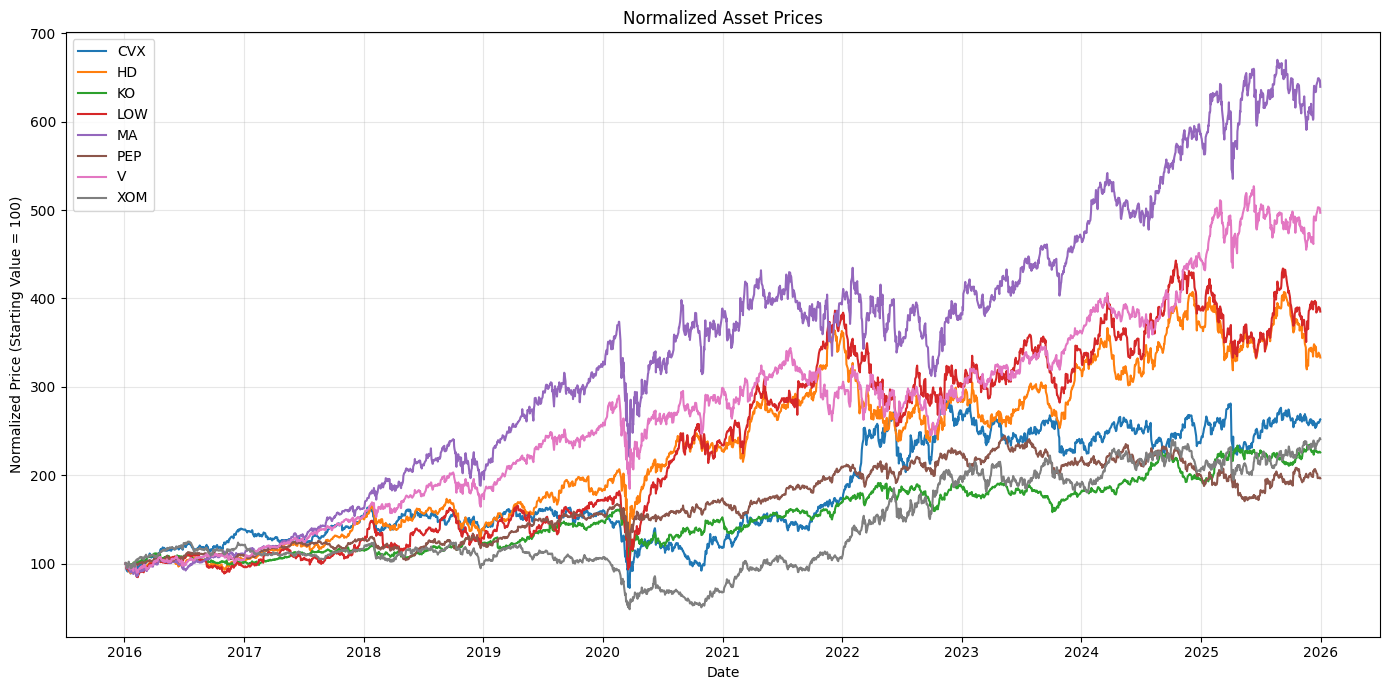

In [18]:
plt.figure(figsize=(14, 7))

for ticker in normalized_prices.columns:
    plt.plot(
        normalized_prices.index,
        normalized_prices[ticker],
        label=ticker
    )

plt.title("Normalized Asset Prices")
plt.xlabel("Date")
plt.ylabel("Normalized Price (Starting Value = 100)")
plt.legend()
plt.grid(alpha = 0.3)
plt.tight_layout()

plt.show()

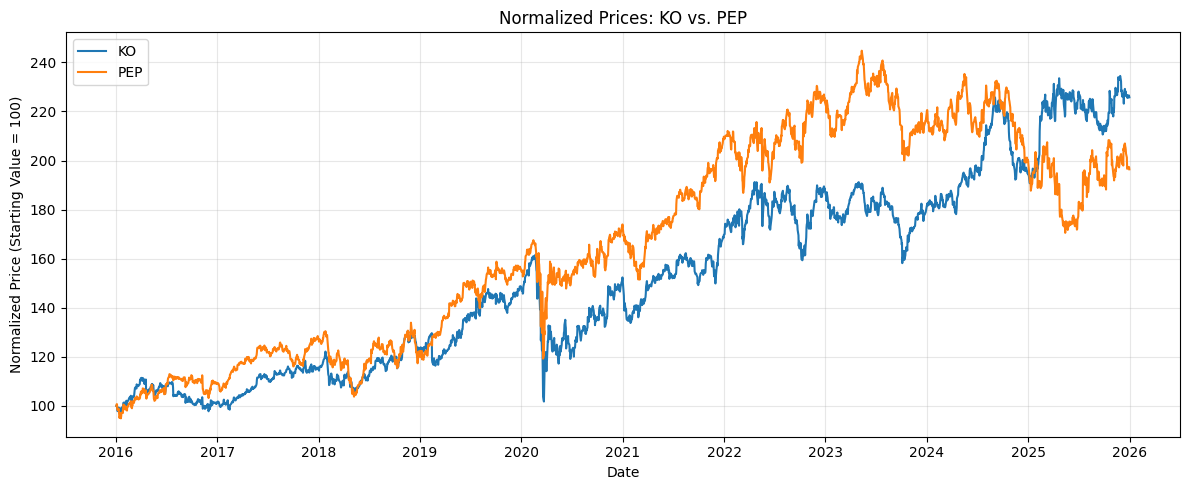

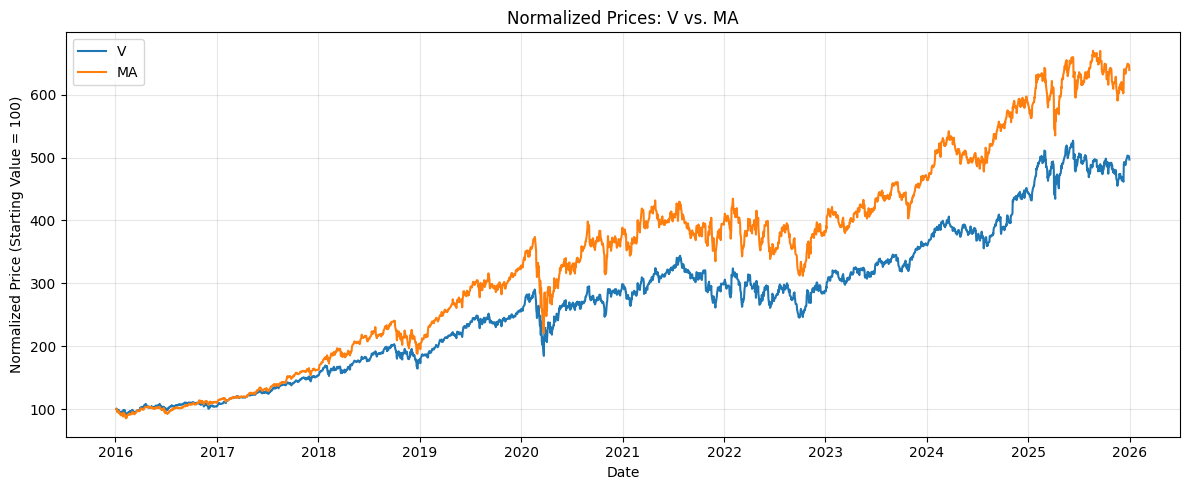

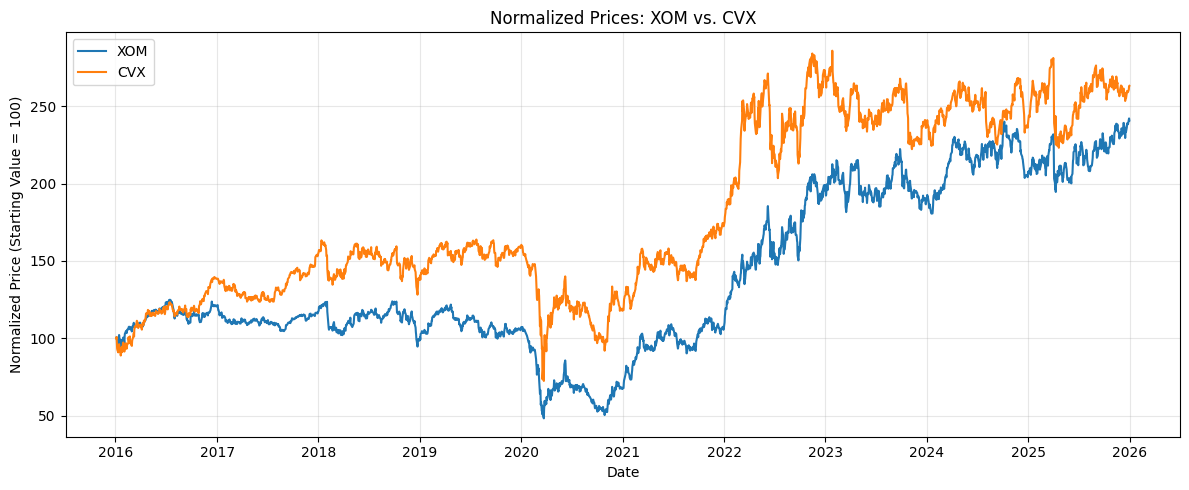

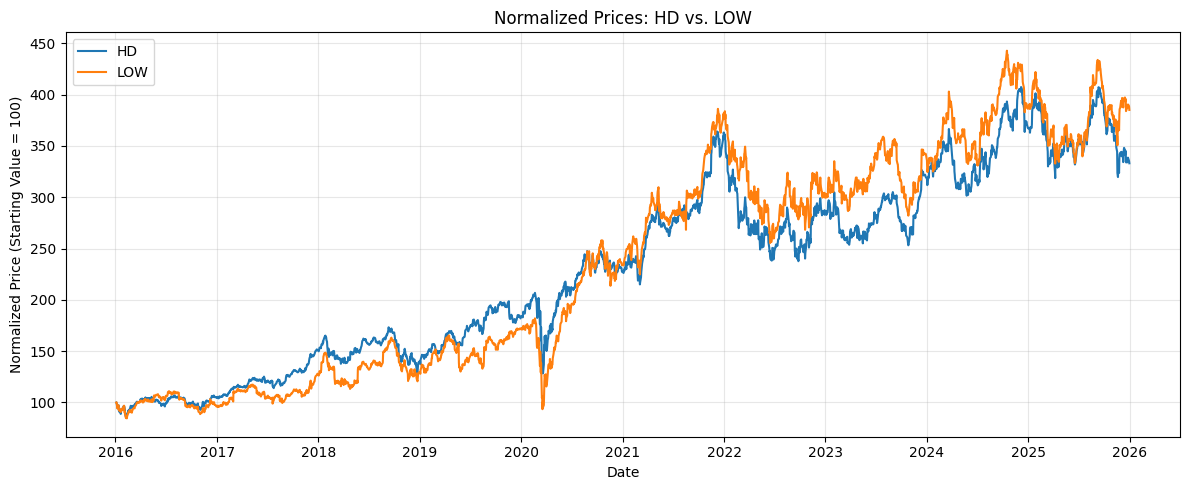

In [19]:
candidate_pairs = [
    ("KO", "PEP"),
    ("V", "MA"),
    ("XOM", "CVX"),
    ("HD", "LOW")
]

for asset_x, asset_y in candidate_pairs:

    pair = normalized_prices[[asset_x, asset_y]]

    plt.figure(figsize=(12, 5))

    plt.plot(pair.index, pair[asset_x], label=asset_x)
    plt.plot(pair.index, pair[asset_y], label=asset_y)

    plt.title(f"Normalized Prices: {asset_x} vs. {asset_y}")
    plt.xlabel("Date")
    plt.ylabel("Normalized Price (Starting Value = 100)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.show()

Correlation and Cointegration Analysis

In [20]:
# split train and test data
train_prices = prices.loc["2016-01-01":"2021-12-31"].copy()
test_prices = prices.loc["2022-01-01":"2025-12-31"].copy()

print("Training period:")
print(train_prices.index.min(), "to", train_prices.index.max())

print("\nTesting period:")
print(test_prices.index.min(), "to", test_prices.index.max())

print("\nTraining observations:", len(train_prices))
print("Testing observations:", len(test_prices))

Training period:
2016-01-04 00:00:00 to 2021-12-31 00:00:00

Testing period:
2022-01-03 00:00:00 to 2025-12-31 00:00:00

Training observations: 1511
Testing observations: 1003


In [21]:
train_returns = np.log(
    train_prices / train_prices.shift(1)
).dropna()

train_returns.head()

Ticker,CVX,HD,KO,LOW,MA,PEP,V,XOM
Date,,,,,,,,
2016-01-05,0.008517,-0.004895,0.003531,0.002123,0.001897,0.006861,0.007502,0.008485
2016-01-06,-0.040306,-0.010404,-0.005421,-0.020084,-0.015413,0.000302,-0.013198,-0.008355
2016-01-07,-0.036080,-0.028924,-0.016679,-0.025616,-0.018488,-0.019387,-0.019859,-0.016136
2016-01-08,-0.010778,-0.012034,-0.002646,-0.016649,-0.019281,-0.003696,-0.012409,-0.020409
2016-01-11,-0.016698,0.015059,0.001685,0.025078,0.007647,0.002363,0.014170,-0.013479


In [22]:
correlation_results = []

for asset_1, asset_2 in candidate_pairs:
    correlation = train_returns[asset_1].corr(
        train_returns[asset_2]
    )

    correlation_results.append({
        "Pair": f"{asset_1}/{asset_2}",
        "Return Correlation": correlation
    })

correlation_df = pd.DataFrame(correlation_results)

correlation_df

,Pair,Return Correlation
0,KO/PEP,0.738346
1,V/MA,0.907057
2,XOM/CVX,0.827752
3,HD/LOW,0.798335


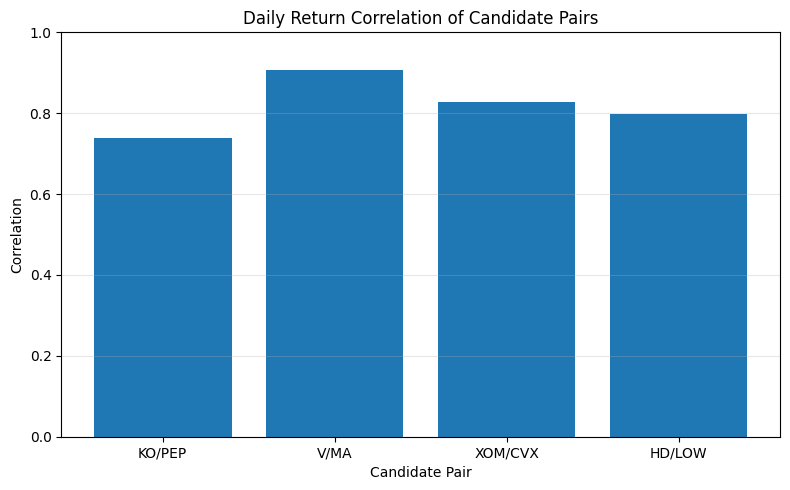

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(
    correlation_df["Pair"],
    correlation_df["Return Correlation"]
)

plt.title("Daily Return Correlation of Candidate Pairs")
plt.xlabel("Candidate Pair")
plt.ylabel("Correlation")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

The Engle Granger test starts with H_0: The two price series are not cointegrated

Our initial significance level is: alpha = 0.5

Therefore if p < 0.05 we reject the H_0. That gives us evidence that the pair is cointegrated.
If p >= 0.05 we fail to reject H_0. We do not have sufficient evidence of cointegration.

In [ ]:
from statsmodels.tsa.stattools import coint

log_train_prices = np.log(train_prices)

cointegration_results = []

for asset_1, asset_2 in candidate_pairs:
    
    test_statistic, p_value, critical_values = coint(
        log_train_prices[asset_1],
        log_train_prices[asset_2]
    )

    cointegration_results.append({
        "Pair": f"{asset_1}/{asset_2}",
        "Test Statistic": test_statistic,
        "p-value": p_value
    })

cointegration_df = pd.DataFrame(cointegration_results)

cointegration_df

,Pair,Test Statistic,p-value
0,KO/PEP,-3.249241,0.062072
1,V/MA,-4.253584,0.003021
2,XOM/CVX,-1.379499,0.804454
3,HD/LOW,-2.611376,0.232272


In [26]:
pair_analysis = correlation_df.merge(
    cointegration_df,
    on="Pair"
)

pair_analysis = pair_analysis.sort_values(
    "p-value"
)

pair_analysis

,Pair,Return Correlation,Test Statistic,p-value
1,V/MA,0.907057,-4.253584,0.003021
0,KO/PEP,0.738346,-3.249241,0.062072
3,HD/LOW,0.798335,-2.611376,0.232272
2,XOM/CVX,0.827752,-1.379499,0.804454


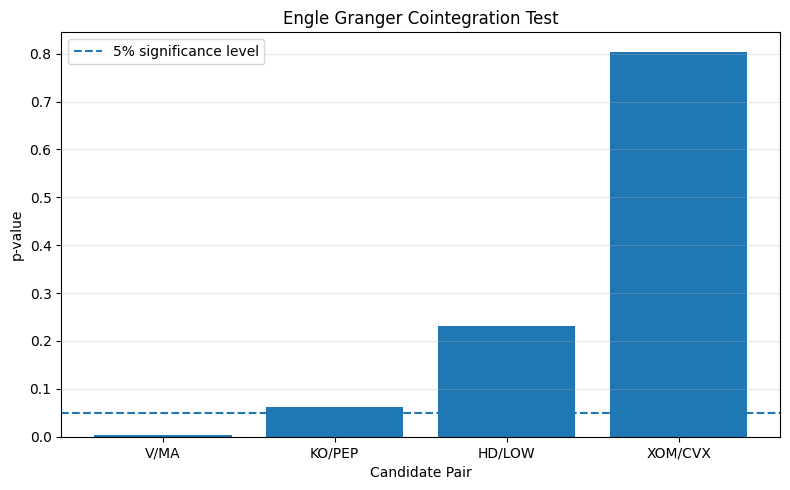

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    pair_analysis["Pair"],
    pair_analysis["p-value"]
)

plt.axhline(
    y=0.05,
    linestyle="--",
    label="5% significance level"
)

plt.title("Engle Granger Cointegration Test")
plt.xlabel("Candidate Pair")
plt.ylabel("p-value")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()